# Figure 2

Panels a and b are schematics. This notebook draws the heatmaps of panels c (seen PTMs) and d (unseen PTMs) from the source data: 95th percentile of the absolute ΔiRT and median spectral angle per PTM and PTM encoding.

Data: `Wilhelm_SourceData.xlsx` (one worksheet per panel) and the `Wilhelm_SourceData_*.parquet` / `*.csv` files of the figshare deposit (column descriptions in the deposit's `README.md`). Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; while the article is private also `FIGSHARE_TOKEN`) to download the files into `./data`, or set `SOURCE_DATA_DIR` to a local copy of the deposit.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'Fig2'
FIG_DIR.mkdir(parents=True, exist_ok=True)


ROWS = ['AA only', 'Naive', 'Delta mass', 'Atom count', 'Gain Loss']


def sa_heatmap(sheet, title):
    df = table(sheet)
    cols = list(dict.fromkeys(df['PTM']))
    pt = df.pivot(index='PTM_encoding', columns='PTM', values='median_spectral_angle').loc[ROWS, cols]
    fig, ax = plt.subplots(figsize=(14, 3.6))
    sns.heatmap(pt, annot=True, fmt='.2g', cmap='mako', vmin=0.7, vmax=0.93,
                cbar_kws={'label': 'Spectral Angle'}, ax=ax)
    ax.set_xlabel('FII Prediction Accuracy')
    ax.set_ylabel('PTM Encoding')
    ax.set_title(title)
    plt.yticks(rotation=0)
    plt.tight_layout()
    return pt


def irt_heatmap(sheet, title):
    from matplotlib.colors import LogNorm
    df = table(sheet)
    cols = list(dict.fromkeys(df['PTM']))
    pt = df.pivot(index='PTM_encoding', columns='PTM', values='abs_dIRT_95pct').loc[ROWS, cols]
    fig, ax = plt.subplots(figsize=(14, 3.6))
    sns.heatmap(pt, annot=True, fmt='.2g', cmap='mako_r', norm=LogNorm(vmin=2, vmax=40),
                cbar_kws={'label': 'Absolute ΔiRT 95%', 'ticks': [2, 4, 7, 10, 40], 'format': '%g'}, ax=ax)
    ax.set_xlabel('')
    ax.set_ylabel('PTM Encoding')
    ax.set_title(title)
    plt.yticks(rotation=0)
    plt.tight_layout()
    return pt

## Panel c — seen PTMs, iRT prediction error

95th percentile of the absolute ΔiRT per PTM encoding (table `Fig2c_iRT`); logarithmic colour scale 2–40.

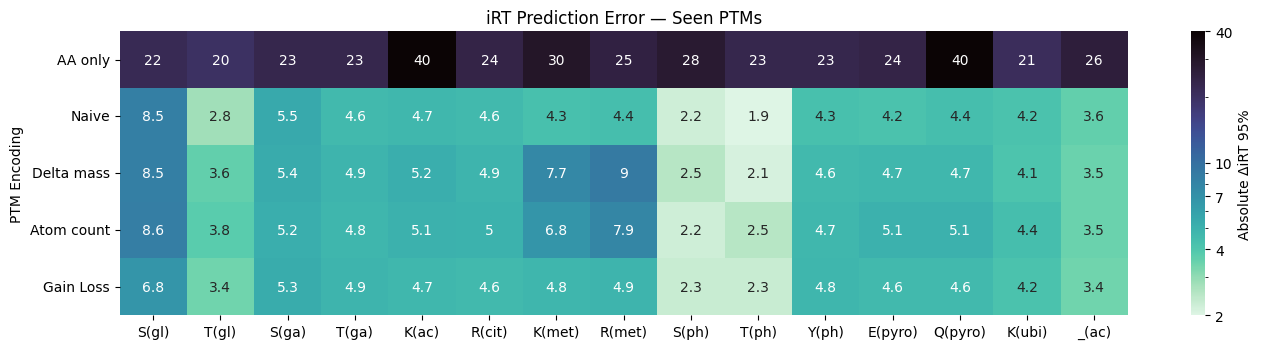

PTM,S(gl),T(gl),S(ga),T(ga),K(ac),R(cit),K(met),R(met),S(ph),T(ph),Y(ph),E(pyro),Q(pyro),K(ubi),_(ac)
PTM_encoding,,,,,,,,,,,,,,,
AA only,22.0,20.0,23.0,23.0,40.0,24.0,30.0,25.0,28.0,23.0,23.0,24.0,40.0,21.0,26.0
Naive,8.5,2.8,5.5,4.6,4.7,4.6,4.3,4.4,2.2,1.9,4.3,4.2,4.4,4.2,3.6
Delta mass,8.5,3.6,5.4,4.9,5.2,4.9,7.7,9.0,2.5,2.1,4.6,4.7,4.7,4.1,3.5
Atom count,8.6,3.8,5.2,4.8,5.1,5.0,6.8,7.9,2.2,2.5,4.7,5.1,5.1,4.4,3.5
Gain Loss,6.8,3.4,5.3,4.9,4.7,4.6,4.8,4.9,2.3,2.3,4.8,4.6,4.6,4.2,3.4


In [3]:
pt = irt_heatmap('Fig2c_iRT', 'iRT Prediction Error — Seen PTMs')
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig2c_iRT.{ext}', dpi=300, bbox_inches='tight')
plt.show()
pt

## Panel d — unseen PTMs, iRT prediction error

95th percentile of the absolute ΔiRT per PTM encoding (table `Fig2d_iRT`); logarithmic colour scale 2–40.

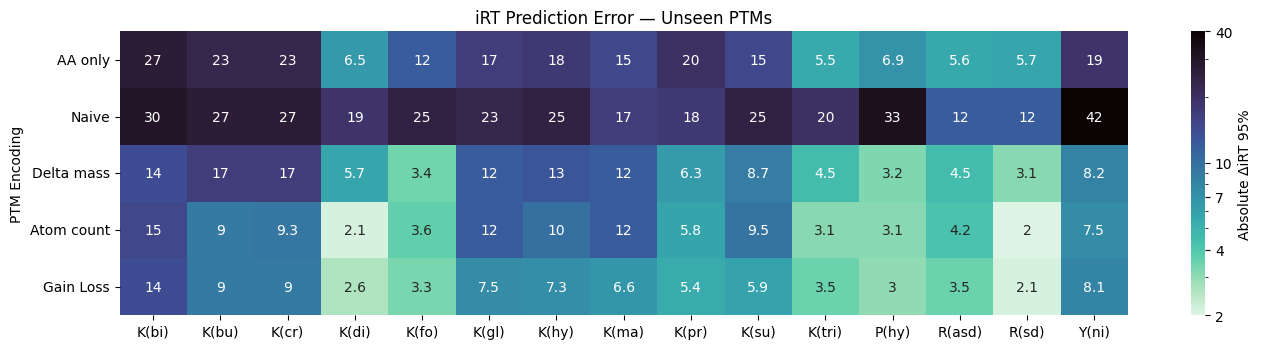

PTM,K(bi),K(bu),K(cr),K(di),K(fo),K(gl),K(hy),K(ma),K(pr),K(su),K(tri),P(hy),R(asd),R(sd),Y(ni)
PTM_encoding,,,,,,,,,,,,,,,
AA only,27.0,23.0,23.0,6.5,12.0,17.0,18.0,15.0,20.0,15.0,5.5,6.9,5.6,5.7,19.0
Naive,30.0,27.0,27.0,19.0,25.0,23.0,25.0,17.0,18.0,25.0,20.0,33.0,12.0,12.0,42.0
Delta mass,14.0,17.0,17.0,5.7,3.4,12.0,13.0,12.0,6.3,8.7,4.5,3.2,4.5,3.1,8.2
Atom count,15.0,9.0,9.3,2.1,3.6,12.0,10.0,12.0,5.8,9.5,3.1,3.1,4.2,2.0,7.5
Gain Loss,14.0,9.0,9.0,2.6,3.3,7.5,7.3,6.6,5.4,5.9,3.5,3.0,3.5,2.1,8.1


In [4]:
pt = irt_heatmap('Fig2d_iRT', 'iRT Prediction Error — Unseen PTMs')
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig2d_iRT.{ext}', dpi=300, bbox_inches='tight')
plt.show()
pt

## Panel c — seen PTMs, spectral angle

Median spectral angle per PTM encoding (table `Fig2c_spectral_angle`); colour scale 0.70–0.93.

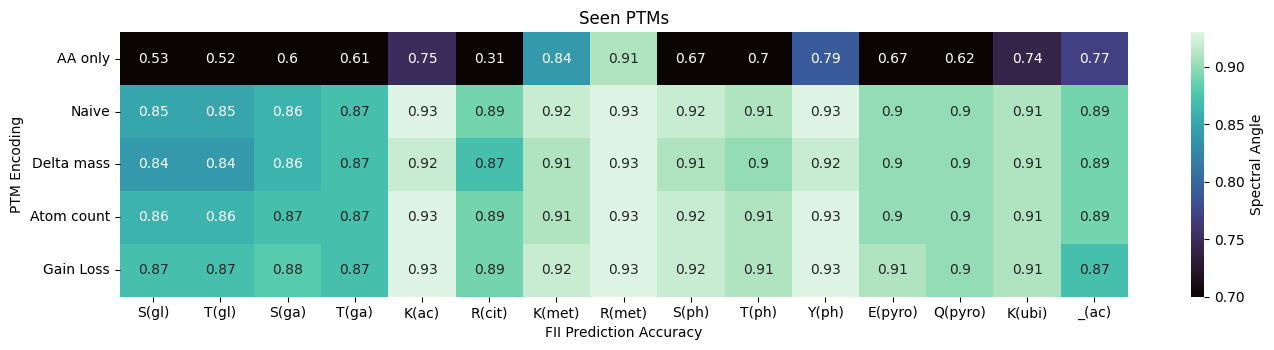

PTM,S(gl),T(gl),S(ga),T(ga),K(ac),R(cit),K(met),R(met),S(ph),T(ph),Y(ph),E(pyro),Q(pyro),K(ubi),_(ac)
PTM_encoding,,,,,,,,,,,,,,,
AA only,0.53,0.52,0.60,0.61,0.75,0.31,0.84,0.91,0.67,0.70,0.79,0.67,0.62,0.74,0.77
Naive,0.85,0.85,0.86,0.87,0.93,0.89,0.92,0.93,0.92,0.91,0.93,0.90,0.90,0.91,0.89
Delta mass,0.84,0.84,0.86,0.87,0.92,0.87,0.91,0.93,0.91,0.90,0.92,0.90,0.90,0.91,0.89
Atom count,0.86,0.86,0.87,0.87,0.93,0.89,0.91,0.93,0.92,0.91,0.93,0.90,0.90,0.91,0.89
Gain Loss,0.87,0.87,0.88,0.87,0.93,0.89,0.92,0.93,0.92,0.91,0.93,0.91,0.90,0.91,0.87


In [5]:
pt = sa_heatmap('Fig2c_spectral_angle', 'Seen PTMs')
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig2c_spectral_angle.{ext}', dpi=300, bbox_inches='tight')
plt.show()
pt

## Panel d — unseen PTMs, spectral angle

Median spectral angle per PTM encoding (table `Fig2d_spectral_angle`); colour scale 0.70–0.93.

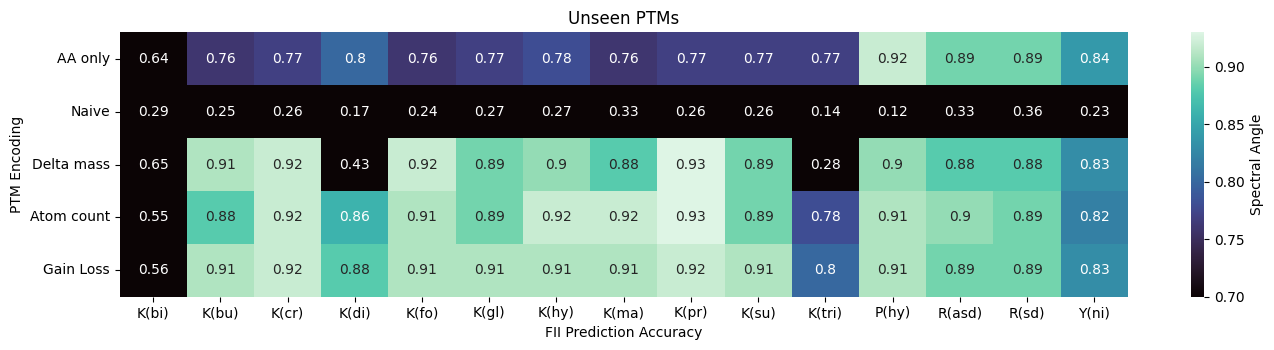

PTM,K(bi),K(bu),K(cr),K(di),K(fo),K(gl),K(hy),K(ma),K(pr),K(su),K(tri),P(hy),R(asd),R(sd),Y(ni)
PTM_encoding,,,,,,,,,,,,,,,
AA only,0.64,0.76,0.77,0.80,0.76,0.77,0.78,0.76,0.77,0.77,0.77,0.92,0.89,0.89,0.84
Naive,0.29,0.25,0.26,0.17,0.24,0.27,0.27,0.33,0.26,0.26,0.14,0.12,0.33,0.36,0.23
Delta mass,0.65,0.91,0.92,0.43,0.92,0.89,0.90,0.88,0.93,0.89,0.28,0.90,0.88,0.88,0.83
Atom count,0.55,0.88,0.92,0.86,0.91,0.89,0.92,0.92,0.93,0.89,0.78,0.91,0.90,0.89,0.82
Gain Loss,0.56,0.91,0.92,0.88,0.91,0.91,0.91,0.91,0.92,0.91,0.80,0.91,0.89,0.89,0.83


In [6]:
pt = sa_heatmap('Fig2d_spectral_angle', 'Unseen PTMs')
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig2d_spectral_angle.{ext}', dpi=300, bbox_inches='tight')
plt.show()
pt